# Proyecto final de Ciencia de Datos
## Clasificación supervisada con Naive Bayes, SVM y red neuronal — *Bank Marketing* (UCI)
### Parte 1 · Datos y preparación

**Curso:** Ciencia de Datos · **Instructor:** M. en C. Benito Samuel López Razo
**Autores:** _(escribe aquí tu nombre y el de tu equipo)_ · **Semilla global:** 42

Este notebook cubre la sección **2.1 "Datos y preparación"** del proyecto: describir el problema y los datos, hacer el análisis exploratorio (EDA), limpiar, codificar, escalar y dividir en *train / validation / test* **sin filtrar información del conjunto de prueba**.

Los modelos (regresión logística de referencia, Naive Bayes, SVM y red neuronal) se agregarán **en este mismo notebook**, a continuación de esta parte, usando los conjuntos `X_train`, `X_val`, `X_test` y el `preprocesador` que se definen aquí.

**Índice**

0. El problema
1. Configuración y reproducibilidad
2. Carga de datos y diccionario de variables
3. Calidad de los datos
4. Análisis exploratorio (EDA)
5. Limpieza y decisiones de preparación
6. División train / validation / test
7. Preprocesamiento (codificación + escalado) ajustado solo con *train*
8. Verificación anti-fuga de información
9. Guardado de tablas y metadatos
10. Resumen de decisiones (insumo para la sección *Metodología* del reporte)

## 0. El problema

Los datos provienen de campañas de **telemarketing de un banco portugués** (2008–2010). Cada fila es una llamada a un cliente y la variable objetivo `y` indica si el cliente **contrató un depósito a plazo** (`yes`) o no (`no`).

- **Tipo de problema:** clasificación binaria supervisada.
- **Motivación:** llamar a todos los clientes es caro; un modelo que priorice a quienes tienen más probabilidad de aceptar reduce costos y mejora la conversión.
- **Reto principal:** las clases están **desbalanceadas** (la mayoría dice que no), así que la exactitud por sí sola engaña. Por eso más adelante se usarán precisión, recall, F1, ROC y curva precisión-recall.

> Fuente del dataset: UCI Machine Learning Repository, *Bank Marketing* (id 222); los datos están en la carpeta `data/`.
> Cita solicitada por los autores del dataset (ver `data/bank-names.txt`): S. Moro, R. Laureano y P. Cortez, "Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology," en *Proc. European Simulation and Modelling Conference (ESM'2011)*, Guimarães, Portugal, oct. 2011, pp. 117–121.
> Trabajo relacionado útil para el reporte: S. Moro, P. Cortez y P. Rita, "A data-driven approach to predict the success of bank telemarketing," *Decision Support Systems*, vol. 62, pp. 22–31, 2014.

## 1. Configuración y reproducibilidad

Aquí se importan las librerías y se fijan **la semilla, las rutas y las decisiones configurables**. Todo lo aleatorio del proyecto (división de datos, modelos, validación cruzada) debe usar `SEED`, así quien ejecute el código obtiene los mismos resultados.

Las tres banderas de la sección "decisiones configurables" son las que más afectan al resultado; cada una se justifica en la sección 5 y 7.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

warnings.filterwarnings("ignore")

# ---------- Reproducibilidad ----------
SEED = 42
np.random.seed(SEED)

# ---------- Rutas ----------
DATA = Path("data") / "bank-full.csv"
FIGURAS = Path("figuras")
RESULTADOS = Path("resultados")
for carpeta in (FIGURAS, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

# ---------- Decisiones configurables ----------
TEST_SIZE = 0.15          # proporción para prueba
VAL_SIZE = 0.15           # proporción para validación (del total)
EXCLUIR_DURATION = True   # True = modelo realista (ver sección 5.4)
USAR_YEO_JOHNSON = False  # False = StandardScaler, True = Yeo-Johnson + estandarizar

# ---------- Estilo de gráficas ----------
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})


def guardar(fig, nombre):
    # Guarda la figura en alta resolución para usarla en el reporte IEEE.
    fig.savefig(FIGURAS / f"{nombre}.png")
    print(f"Figura guardada: {FIGURAS / nombre}.png")


def guardar_tabla(tabla, nombre):
    # Guarda una tabla en CSV (utf-8-sig para que Excel respete los acentos).
    tabla.to_csv(RESULTADOS / f"{nombre}.csv", encoding="utf-8-sig")
    print(f"Tabla guardada: {RESULTADOS / nombre}.csv")

## 2. Carga de datos y diccionario de variables

El dataset viene en la carpeta `data/` (es el zip *bank* del UCI):

| Archivo | Qué es | ¿Se usa? |
|---|---|---|
| `bank-full.csv` | Los 45,211 registros, ordenados por fecha (mayo 2008 – noviembre 2010) | **Sí, es el dataset del proyecto** |
| `bank.csv` | Muestra aleatoria del 10 % de `bank-full.csv` (4,521 filas) | No: todas sus filas ya están en `bank-full.csv`, así que mezclarlos duplicaría datos |
| `bank-names.txt` | Documentación oficial: variables, significado y cita | Solo como referencia |

La función `cargar_bank_marketing()` lee `data/bank-full.csv` (separador `;`) y limpia espacios y mayúsculas en las columnas de texto. Si no encuentra el archivo, detiene la ejecución con un mensaje claro.

**Diccionario de variables**

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad del cliente |
| `job` | categórica | Ocupación (12 categorías) |
| `marital` | categórica | Estado civil |
| `education` | categórica | Nivel educativo |
| `default` | binaria | ¿Tiene crédito en incumplimiento? |
| `balance` | numérica | Saldo anual promedio (euros) |
| `housing` | binaria | ¿Tiene crédito hipotecario? |
| `loan` | binaria | ¿Tiene préstamo personal? |
| `contact` | categórica | Medio del último contacto |
| `day` | numérica | Día del mes del último contacto |
| `month` | categórica | Mes del último contacto |
| `duration` | numérica | Duración del último contacto (segundos) |
| `campaign` | numérica | Contactos en esta campaña a este cliente |
| `pdays` | numérica | Días desde el último contacto de una campaña previa (`-1` = nunca contactado) |
| `previous` | numérica | Contactos antes de esta campaña |
| `poutcome` | categórica | Resultado de la campaña previa |
| `y` | **objetivo** | ¿Contrató el depósito a plazo? (`yes` / `no`) |

In [2]:
def cargar_bank_marketing():
    if not DATA.exists():
        raise FileNotFoundError(
            f"No encontré {DATA}. Verifica que este notebook esté en la misma carpeta que 'data/' "
            "y que bank-full.csv esté dentro de 'data/'."
        )
    df = pd.read_csv(DATA, sep=";")
    for col in df.select_dtypes(exclude="number").columns:
        df[col] = df[col].astype(str).str.strip().str.lower()
    return df


df = cargar_bank_marketing()
print(f"Archivo leído: {DATA}")
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Archivo leído: data\bank-full.csv
Filas: 45,211 | Columnas: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Calidad de los datos

Antes de explorar o modelar hay que saber **qué tan sucio está el dataset**. Se revisan cuatro cosas:

- **Tipos de dato:** que las numéricas sean numéricas y las categóricas, texto.
- **Nulos reales:** celdas vacías (`NaN`).
- **Valores `"unknown"`:** en este dataset los faltantes vienen codificados como texto, así que `isna()` no los detecta y hay que contarlos aparte.
- **Duplicados:** filas idénticas que inflarían artificialmente la muestra.

También se cuenta cuántos clientes tienen `pdays = -1`, porque es un **valor centinela** (significa "nunca contactado antes"), no una cantidad real de días.

In [3]:
print("== Tipos de dato ==")
display(df.dtypes.astype(str).to_frame("tipo").T)

print("\n== Nulos reales por columna ==")
nulos = df.isna().sum()
print(nulos[nulos > 0] if nulos.sum() > 0 else "No hay valores NaN.")

print("\n== Valores 'unknown' por columna categórica ==")
cols_cat_eda = df.select_dtypes(exclude="number").columns.drop("y")
unknown = (df[cols_cat_eda] == "unknown").sum().to_frame("n_unknown")
unknown["porcentaje"] = (unknown["n_unknown"] / len(df) * 100).round(2)
unknown = unknown.sort_values("porcentaje", ascending=False)
display(unknown)
guardar_tabla(unknown, "tabla_unknown")

print(f"\n== Filas duplicadas == {df.duplicated().sum()}")

pdays_centinela = (df["pdays"] == -1).mean() * 100
print(f"\n== pdays = -1 (nunca contactado antes) == {pdays_centinela:.2f}% de los registros")

== Tipos de dato ==


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
tipo,int64,str,str,str,str,int64,str,str,str,int64,str,int64,int64,int64,int64,str,str



== Nulos reales por columna ==
No hay valores NaN.

== Valores 'unknown' por columna categórica ==


,n_unknown,porcentaje
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
marital,0,0.00
housing,0,0.00
default,0,0.00
loan,0,0.00
month,0,0.00


Tabla guardada: resultados\tabla_unknown.csv

== Filas duplicadas == 0

== pdays = -1 (nunca contactado antes) == 81.74% de los registros


**Qué muestra tu salida** (borrador: revísalo y reescríbelo con tus palabras para el reporte)**:**

- No hay nulos ni duplicados, pero los faltantes están escondidos como `unknown`: **81.75 %** en `poutcome`, **28.80 %** en `contact`, 4.11 % en `education` y 0.64 % en `job`. Por su volumen **no se imputan**: se conserva `unknown` como una categoría más (justificación en 5.5).
- `pdays = -1` en **81.74 %** de las filas, casi el mismo porcentaje que `poutcome = unknown` (lo esperable: ambas significan "sin campaña previa"). Confirma que la variable mezcla "no aplica" con "días reales"; se corrige en 5.3.

## 4. Análisis exploratorio (EDA)

El PDF pide **al menos tres gráficas interpretadas**. Aquí se generan cinco, todas guardadas en `figuras/` en alta resolución para el reporte IEEE:

| Figura | Qué muestra | Para qué sirve |
|---|---|---|
| Fig. 1 | Proporción de cada clase | Cuantificar el desbalance |
| Fig. 2 | Histogramas de las numéricas | Detectar sesgo y valores extremos |
| Fig. 3 | Numéricas separadas por clase | Ver qué variables distinguen a quien contrata |
| Fig. 4 | % de contratación por categoría | Ver qué categorías pesan más |
| Fig. 5 | Matriz de correlación | Detectar relaciones lineales y redundancia |

### 4.1 Proporción de clases (Fig. 1)

Es lo primero que hay que mirar: define **qué métricas son válidas** y si hará falta ponderar las clases. Se calcula también la razón de desbalance (clase mayoritaria / minoritaria).

,n,%
y,,
no,39922,88.3
yes,5289,11.7


Tabla guardada: resultados\tabla_clases.csv
Razón de desbalance (no : yes) = 7.5 : 1


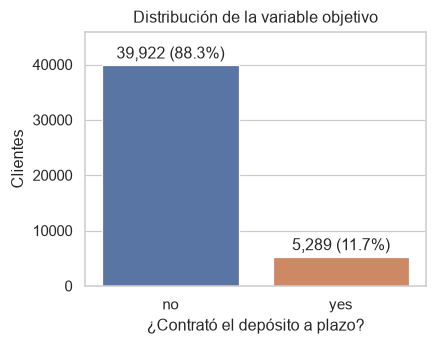

Figura guardada: figuras\fig1_distribucion_clases.png


In [4]:
conteo = df["y"].value_counts()
porcentaje = df["y"].value_counts(normalize=True).mul(100).round(2)
tabla_clases = pd.DataFrame({"n": conteo, "%": porcentaje})
display(tabla_clases)
guardar_tabla(tabla_clases, "tabla_clases")
print(f"Razón de desbalance (no : yes) = {conteo['no'] / conteo['yes']:.1f} : 1")

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(data=df, x="y", order=["no", "yes"], hue="y", legend=False, ax=ax)
for contenedor, clase in zip(ax.containers, ["no", "yes"]):
    ax.bar_label(contenedor, labels=[f"{conteo[clase]:,} ({porcentaje[clase]}%)"], padding=2)
ax.set_xlabel("¿Contrató el depósito a plazo?")
ax.set_ylabel("Clientes")
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_title("Distribución de la variable objetivo")
plt.show()
guardar(fig, "fig1_distribucion_clases")

**Interpretación (borrador con tus datos):** solo 5,289 de 45,211 clientes (**11.70 %**) contrataron el depósito; la razón de desbalance es **7.5 : 1**. Un clasificador que respondiera siempre `no` tendría una exactitud de 88.3 % sin detectar a un solo cliente interesado. Por eso la **exactitud no es una métrica confiable** aquí y se usarán recall, F1, ROC-AUC y precisión-recall; además la división de datos debe ser **estratificada**.

### 4.2 Variables numéricas: distribución (Fig. 2)

Se grafican los histogramas con el **sesgo (skewness)** en el título. Cuando una variable está muy sesgada (|sesgo| > 2) el eje vertical se pone en escala logarítmica para poder ver la cola. Para `pdays` solo se grafican los clientes que sí fueron contactados antes (`pdays ≠ -1`), porque el `-1` aplastaría todo lo demás.

También se cuentan los **outliers según la regla del rango intercuartílico (IQR)**.

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


Tabla guardada: resultados\tabla_descriptivos_numericas.csv


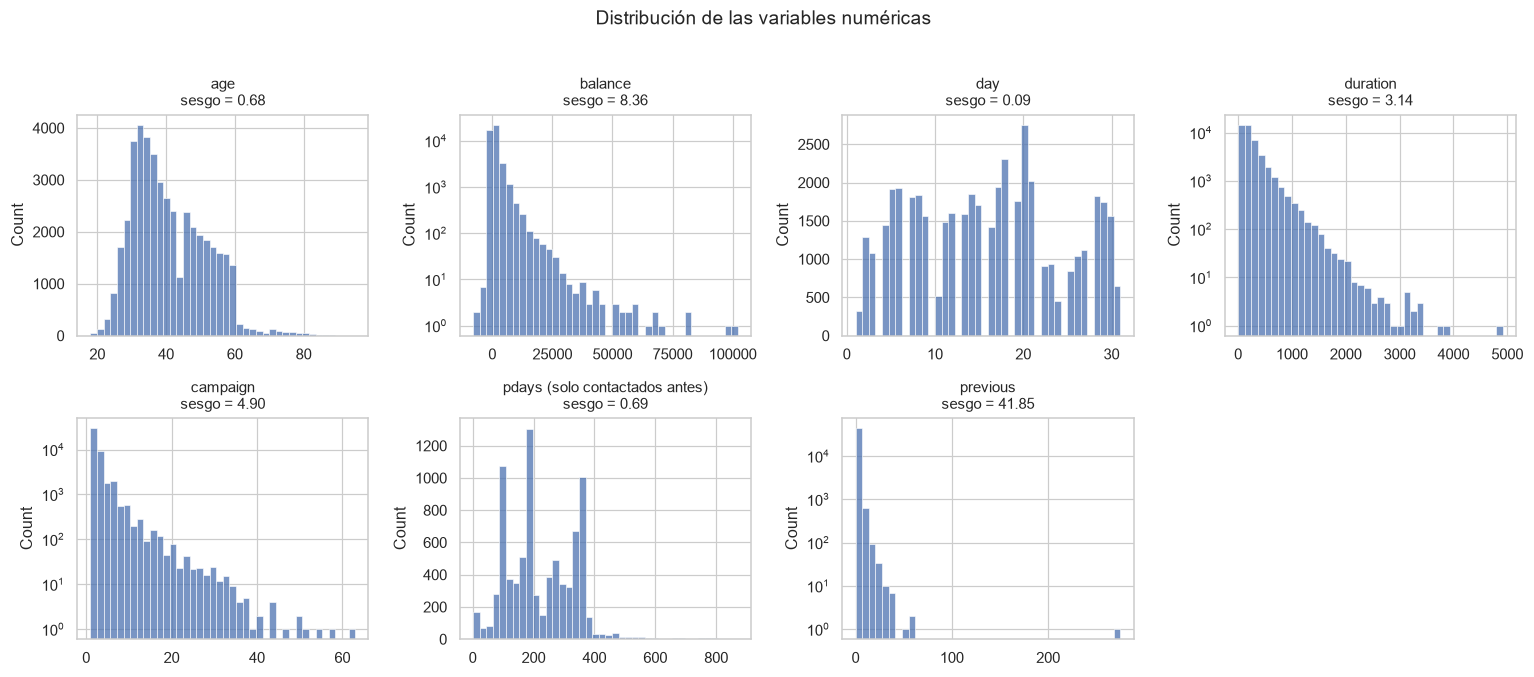

Figura guardada: figuras\fig2_distribucion_numericas.png

Outliers por regla IQR (1.5 x IQR):


,n_outliers,% de filas
age,487,1.08
balance,4729,10.46
day,0,0.00
duration,3235,7.16
campaign,3064,6.78
pdays,8257,18.26
previous,8257,18.26


Tabla guardada: resultados\tabla_outliers_iqr.csv


In [5]:
cols_num_eda = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

descriptivos = df[cols_num_eda].describe().T.round(2)
display(descriptivos)
guardar_tabla(descriptivos, "tabla_descriptivos_numericas")

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), cols_num_eda):
    serie = df.loc[df["pdays"] != -1, col] if col == "pdays" else df[col]
    sesgo = serie.skew()
    sns.histplot(serie, bins=40, ax=ax, color="#4C72B0")
    if abs(sesgo) > 2:
        ax.set_yscale("log")
    titulo = col + (" (solo contactados antes)" if col == "pdays" else "")
    ax.set_title(f"{titulo}\nsesgo = {sesgo:.2f}", fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Distribución de las variables numéricas", y=1.02)
fig.tight_layout()
plt.show()
guardar(fig, "fig2_distribucion_numericas")


def conteo_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())


tabla_out = pd.DataFrame({"n_outliers": {c: conteo_outliers_iqr(df[c]) for c in cols_num_eda}})
tabla_out["% de filas"] = (tabla_out["n_outliers"] / len(df) * 100).round(2)
print("\nOutliers por regla IQR (1.5 x IQR):")
display(tabla_out)
guardar_tabla(tabla_out, "tabla_outliers_iqr")

**Interpretación (borrador con tus datos):** los sesgos más fuertes son `previous` (41.85), `balance` (8.36), `campaign` (4.90), `duration` (3.14) y `pdays` (2.62, inflado por el `-1`; entre quienes sí fueron contactados baja a 0.69). `age` (0.68) y `day` (0.09) son casi simétricas. Los extremos son reales: `balance` va de −8,019 a 102,127 € y `previous` llega a 275 contactos (solo 4 clientes superan 50). Las 8,257 filas "atípicas" de `pdays` y `previous` según la regla IQR son simplemente los clientes contactados antes: más del 75 % de las filas tiene el mismo valor (−1 en `pdays`, 0 en `previous`), así que el IQR vale 0 y la regla marca como atípico todo lo distinto. **No se eliminan** los outliers: son clientes reales y quitarlos sesgaría la muestra. Se mitigan con el escalado; si el sesgo preocupa para algún modelo (sobre todo Naive Bayes gaussiano) se activa `USAR_YEO_JOHNSON = True`.

### 4.3 Variables numéricas frente a la clase (Fig. 3)

Los *boxplots* comparan la distribución de cada numérica entre quienes **no contratan** y quienes **sí contratan**. Una diferencia clara entre cajas indica que la variable ayuda a separar las clases. Se ocultan los puntos extremos (`showfliers=False`) solo para que la caja sea legible.

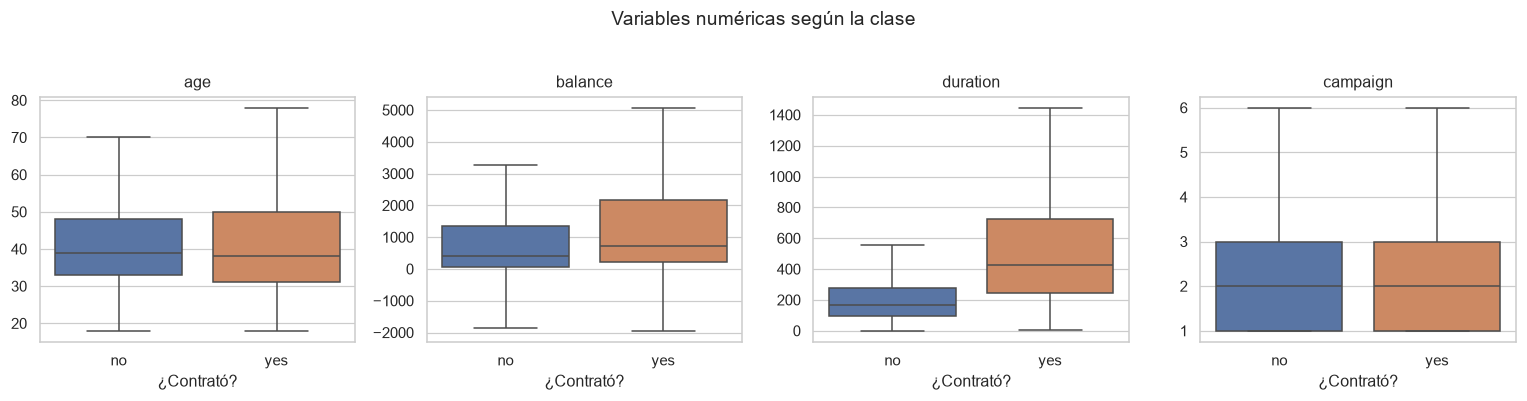

Figura guardada: figuras\fig3_numericas_por_clase.png
Mediana por clase:


,age,balance,duration,campaign,previous
y,,,,,
no,39.0,417.0,164.0,2.0,0.0
yes,38.0,733.0,426.0,2.0,0.0


In [6]:
cols_box = ["age", "balance", "duration", "campaign"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, col in zip(axes, cols_box):
    sns.boxplot(data=df, x="y", y=col, order=["no", "yes"], hue="y", legend=False,
                showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("¿Contrató?")
    ax.set_ylabel("")
fig.suptitle("Variables numéricas según la clase", y=1.03)
fig.tight_layout()
plt.show()
guardar(fig, "fig3_numericas_por_clase")

print("Mediana por clase:")
display(df.groupby("y")[["age", "balance", "duration", "campaign", "previous"]].median())

**Interpretación (borrador con tus datos):** `duration` es la variable numérica que más separa las clases: mediana de **426 s** entre quienes contratan contra **164 s** entre quienes no. El saldo también es mayor (mediana 733 € contra 417 €), mientras que `age`, `campaign` y `previous` casi no cambian (medianas 38 vs 39, 2 vs 2 y 0 vs 0). Aun así `duration` **no se usará como predictor** en el modelo principal, porque solo se conoce **después** de terminar la llamada (ver 5.4).

### 4.4 Variables categóricas frente a la clase (Fig. 4)

Para cada categórica se grafica el **porcentaje de clientes que contrataron** en cada categoría, con una línea punteada en la tasa global. Las categorías por encima de la línea convierten mejor que el promedio. Entre paréntesis, junto a cada categoría, aparece **cuántos clientes hay en ella** (el tamaño importa para no sobreinterpretar tasas altas con pocos casos). `month` se ordena por calendario; las demás, de mayor a menor tasa.

Además se calcula una prueba **chi-cuadrada de independencia** con la clase y la **V de Cramér** (0 = sin asociación, 1 = asociación perfecta). Con 45 mil filas casi cualquier p-valor sale pequeño, así que conviene fijarse sobre todo en **V de Cramér** para comparar la fuerza de la asociación.

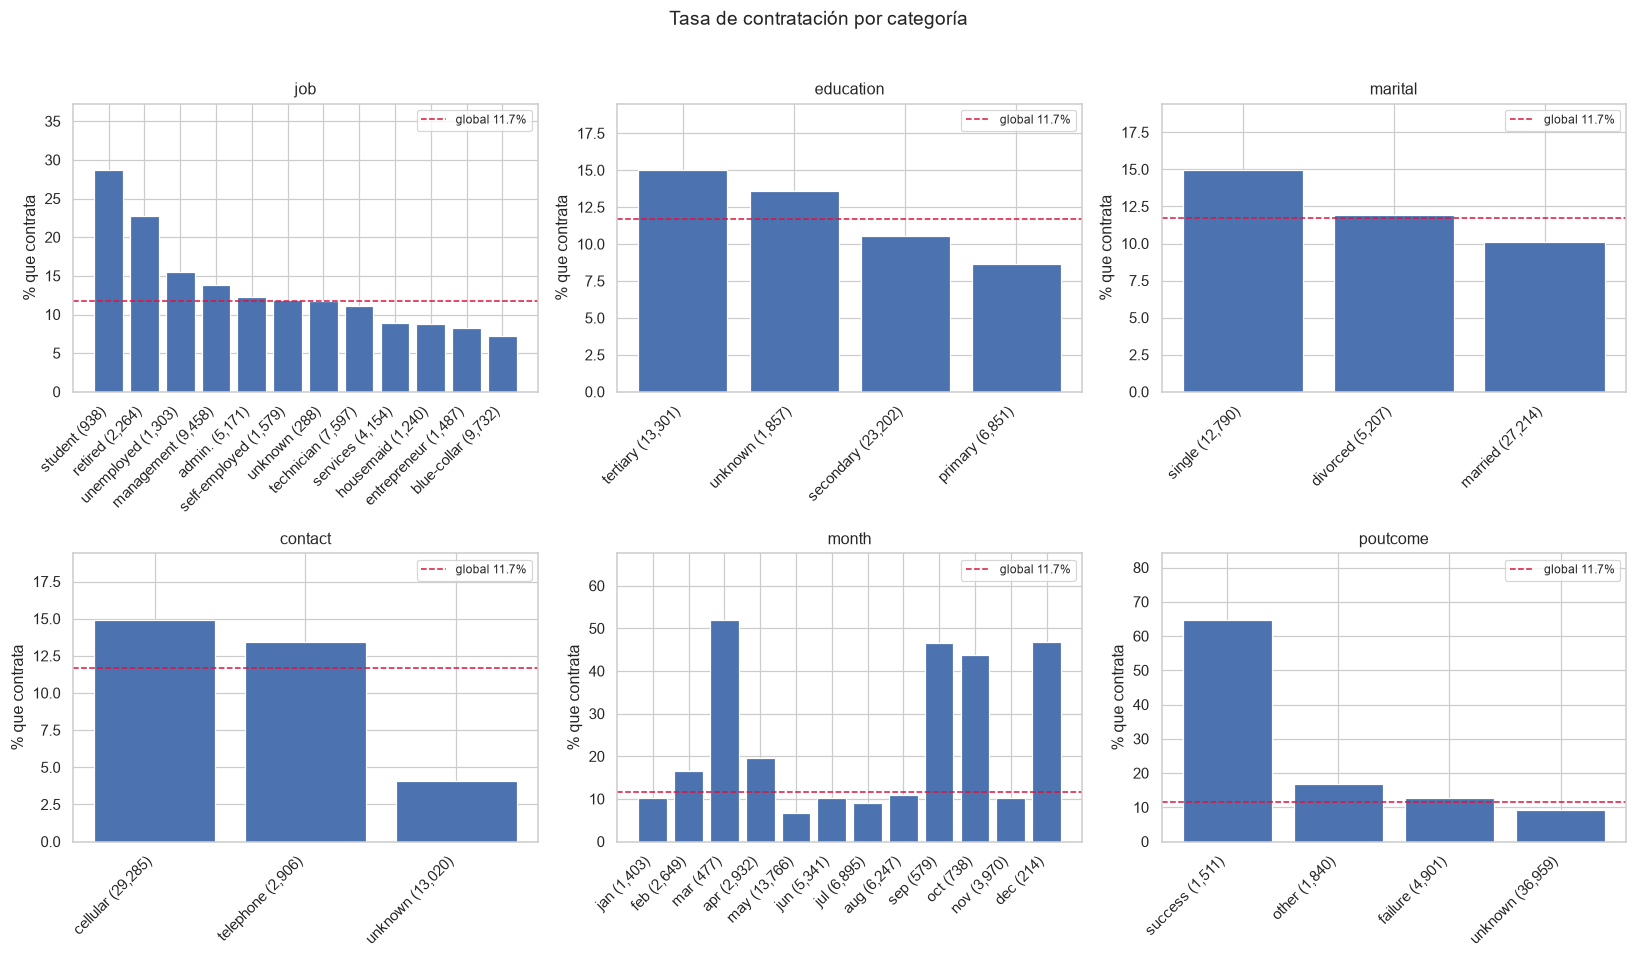

Figura guardada: figuras\fig4_tasa_por_categoria.png


,variable,V de Cramér,p-valor
0,poutcome,0.312,0.00e+00
1,month,0.260,0.00e+00
2,contact,0.151,1.25e-225
3,housing,0.139,2.92e-192
4,job,0.136,3.34e-172
5,education,0.073,1.63e-51
6,loan,0.068,1.67e-47
7,marital,0.066,2.15e-43
8,default,0.022,2.45e-06


Tabla guardada: resultados\tabla_cramers_v.csv


In [7]:
meses = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
tasa_global = (df["y"] == "yes").mean() * 100


def graficar_tasa(ax, col, orden=None):
    tasas = (df["y"] == "yes").groupby(df[col]).mean() * 100
    tasas = tasas.sort_values(ascending=False) if orden is None else tasas.reindex(orden)
    tamanos = df[col].value_counts()
    ax.bar(range(len(tasas)), tasas.values, color="#4C72B0")
    ax.set_xticks(range(len(tasas)))
    ax.set_xticklabels([f"{c} ({tamanos[c]:,})" for c in tasas.index])
    ax.axhline(tasa_global, color="crimson", ls="--", lw=1, label=f"global {tasa_global:.1f}%")
    ax.set_title(col)
    ax.set_ylabel("% que contrata")
    ax.tick_params(axis="x", rotation=45)
    for etiqueta in ax.get_xticklabels():
        etiqueta.set_ha("right")
    ax.set_ylim(0, max(tasas.max(), tasa_global) * 1.3)
    ax.legend(fontsize=8, loc="upper right")


paneles = [("job", None), ("education", None), ("marital", None),
           ("contact", None), ("month", meses), ("poutcome", None)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (col, orden) in zip(axes.ravel(), paneles):
    graficar_tasa(ax, col, orden)
fig.suptitle("Tasa de contratación por categoría", y=1.02)
fig.tight_layout()
plt.show()
guardar(fig, "fig4_tasa_por_categoria")


def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k)), p


filas = []
for col in cols_cat_eda:
    v, p = cramers_v(df[col], df["y"])
    filas.append({"variable": col, "V de Cramér": round(v, 3), "p-valor": f"{p:.2e}"})
tabla_v = pd.DataFrame(filas).sort_values("V de Cramér", ascending=False).reset_index(drop=True)
display(tabla_v)
guardar_tabla(tabla_v, "tabla_cramers_v")

**Interpretación (borrador con tus datos):** la asociación más fuerte con la contratación es la de `poutcome` (V de Cramér = 0.312), seguida de `month` (0.260), `contact` (0.151), `housing` (0.139) y `job` (0.136); `default` casi no aporta (0.022). Los clientes con resultado previo `success` contratan alrededor de **65 %** frente al 11.7 % global; los estudiantes (~29 %) y los jubilados (~23 %) superan al resto; con educación terciaria contrata ~15 % contra ~8.6 % con primaria; y con contacto `unknown` solo ~4 %. Ojo con los meses: marzo, septiembre, octubre y diciembre llegan a 44–52 %, pero son los de **menos contactos** (el número entre paréntesis en cada barra), mientras que mayo concentra 13,766 contactos con solo 6.7 %. Por eso conviene mencionar el tamaño de la categoría antes de concluir que "en marzo se vende más"; además `month` puede reflejar cómo se organizó la campaña, no un efecto causal.

### 4.5 Correlaciones (Fig. 5)

La matriz de correlación de Pearson entre las numéricas y la clase (codificada como 0/1) permite ver **qué variables se relacionan linealmente con el objetivo** y si hay **redundancia entre predictores**. Es relevante sobre todo para Naive Bayes, que supone independencia entre variables.

Se imprimen además los cinco pares de variables más correlacionados entre sí.

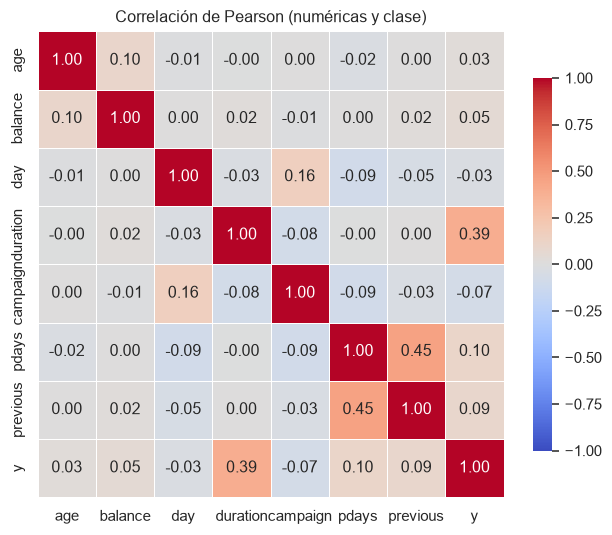

Figura guardada: figuras\fig5_correlaciones.png
Pares más correlacionados:


,,|r|
pdays,previous,0.455
duration,y,0.395
day,campaign,0.162
pdays,y,0.104
age,balance,0.098


In [8]:
df_corr = df[cols_num_eda].assign(y=(df["y"] == "yes").astype(int))
corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlación de Pearson (numéricas y clase)")
plt.show()
guardar(fig, "fig5_correlaciones")

pares = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Pares más correlacionados:")
display(pares.sort_values(ascending=False).head(5).round(3).to_frame("|r|"))

**Interpretación (borrador con tus datos):** la correlación lineal más alta con `y` es la de `duration` (r = 0.395); las demás son bajas (`pdays` 0.10, `previous` 0.09, `campaign` −0.07, `balance` 0.05). Es normal: muchas relaciones son categóricas o no lineales, y por eso tiene sentido probar un kernel RBF y una red neuronal. Entre predictores, `pdays` y `previous` son los más correlacionados (0.455): ambos describen la campaña anterior, así que hay algo de redundancia, pero no la suficiente para quitar una. Recuerda que en esta figura `pdays` todavía trae el `-1` sin tratar (se corrige en 5.3), así que esa correlación es solo una referencia.

### 4.6 Hallazgos del EDA para el reporte

Resumen de lo que encontró el EDA con **tus** datos (úsalo como guion para el reporte, con tus palabras):

1. **Desbalance fuerte:** 11.70 % de los clientes contrata (razón 7.5 : 1). Obliga a estratificar y a usar métricas distintas de la exactitud.
2. **`pdays = -1`** en 81.74 % de las filas: es un código de "no aplica", no un número de días.
3. **`unknown` frecuente** en `poutcome` (81.75 %) y `contact` (28.80 %); con contacto `unknown` solo contrata ~4 %, así que la ausencia de información sí es informativa.
4. **`duration` separa mucho las clases** (r = 0.395; mediana 426 s contra 164 s) **pero genera fuga de información**: se excluye del modelo principal.
5. **Variables muy sesgadas** (`previous`, `balance`, `campaign`): requieren escalado y posiblemente Yeo-Johnson.
6. **`poutcome` y `month`** son las categóricas más asociadas con la contratación (V de Cramér 0.312 y 0.260); ojo con el tamaño de cada mes.
7. **El archivo está ordenado por fecha** (de mayo de 2008 a noviembre de 2010): la división aleatoria de la sección 6 mezcla periodos y conviene mencionarlo como limitación.

## 5. Limpieza y decisiones de preparación

Aquí se transforman los datos según lo que reveló el EDA. Cada decisión se documenta porque el PDF evalúa **qué tan bien se justifican las decisiones**, no solo el resultado.

### 5.1 Variable objetivo binaria
`y` pasa de `no/yes` a `0/1` (la clase positiva, `1`, es "contrató"). Es el formato que esperan los modelos y las métricas (recall y precisión se calculan sobre la clase positiva).

### 5.2 Duplicados
Se eliminan las filas idénticas, si las hay.

### 5.3 `pdays`: tratar el valor centinela
Se crea la variable binaria **`pdays_contactado`** (1 si el cliente fue contactado en una campaña anterior) y en `pdays` se reemplaza `-1` por `0`. Así el `-1` no se interpreta como "−1 días" y la información de "nunca contactado" queda en una variable explícita.

### 5.4 `duration`: evitar fuga de información
La documentación del UCI advierte que `duration` **no se conoce antes de llamar** y que determina casi por completo el resultado (si la llamada dura segundos, el cliente colgó). Usarla daría una exactitud irreal. Con `EXCLUIR_DURATION = True` se elimina del modelo principal. Si quieres reportar la comparación "con y sin `duration`" como experimento extra, basta con poner la bandera en `False` y volver a ejecutar.

### 5.5 `unknown`: conservar como categoría
No se imputan los `unknown`. En `contact` y `poutcome` representan "no se registró", que puede ser informativo, y en las demás son pocos. Como todas las categóricas se codifican con *one-hot*, `unknown` queda como una columna más.

### 5.6 Outliers
No se eliminan (son clientes reales); se mitigan con el escalado.

In [9]:
df_limpio = df.copy()

# 5.1 Objetivo binario
df_limpio["y"] = df_limpio["y"].map({"no": 0, "yes": 1}).astype(int)

# 5.2 Duplicados
antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)
print(f"5.2 Duplicados eliminados: {antes - len(df_limpio)}")

# 5.3 pdays: variable indicadora + reemplazo del valor centinela
df_limpio["pdays_contactado"] = (df_limpio["pdays"] != -1).astype(int)
df_limpio.loc[df_limpio["pdays"] == -1, "pdays"] = 0
print(f"5.3 Clientes contactados antes: {df_limpio['pdays_contactado'].sum():,}")

# 5.4 duration: fuga de información
if EXCLUIR_DURATION:
    df_limpio = df_limpio.drop(columns=["duration"])
    print("5.4 Columna 'duration' excluida del modelo principal.")
else:
    print("5.4 Columna 'duration' CONSERVADA (experimento no realista).")

# Validaciones finales
assert df_limpio.isna().sum().sum() == 0, "Quedaron valores nulos"
assert set(df_limpio["y"].unique()) == {0, 1}, "El objetivo no es binario"
print(f"\nDataset limpio: {df_limpio.shape[0]:,} filas x {df_limpio.shape[1]} columnas")
df_limpio.head()

5.2 Duplicados eliminados: 0
5.3 Clientes contactados antes: 8,257
5.4 Columna 'duration' excluida del modelo principal.

Dataset limpio: 45,211 filas x 17 columnas


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y,pdays_contactado
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,0,0,unknown,0,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,0,0,unknown,0,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,0,0,unknown,0,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,0,0,unknown,0,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,0,0,unknown,0,0


## 6. División train / validation / test

Se divide en tres conjuntos con **semilla fija** y **estratificación** por la clase, para que cada conjunto conserve la misma proporción de `yes`:

- **Train (70 %)**: ajusta el preprocesamiento y entrena los modelos. La validación cruzada para los hiperparámetros se hará **dentro de este conjunto**.
- **Validation (15 %)**: apoyo para decisiones como la detención temprana de la red neuronal o el umbral de decisión.
- **Test (15 %)**: se usa **una sola vez**, al final, para reportar las métricas.

La división se hace **antes** de cualquier ajuste del preprocesamiento. Si se escalara con todos los datos, el promedio y la desviación del conjunto de prueba influirían en el entrenamiento (*data leakage*).

In [10]:
X = df_limpio.drop(columns="y")
y = df_limpio["y"]

# Primero se aparta el conjunto de prueba
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

# Del resto se separa validación (la proporción se reajusta sobre lo que queda)
val_relativo = VAL_SIZE / (1 - TEST_SIZE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_relativo, stratify=y_temp, random_state=SEED
)

resumen_split = pd.DataFrame({
    "filas": [len(X_train), len(X_val), len(X_test)],
    "% del total": [round(len(s) / len(X) * 100, 1) for s in (X_train, X_val, X_test)],
    "% clase 'yes'": [round(s.mean() * 100, 2) for s in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
display(resumen_split)
guardar_tabla(resumen_split, "tabla_division_datos")

,filas,% del total,% clase 'yes'
train,31647,70.0,11.70
validation,6782,15.0,11.69
test,6782,15.0,11.69


Tabla guardada: resultados\tabla_division_datos.csv


**Qué verificar:** la columna `% clase 'yes'` debe ser prácticamente igual en los tres conjuntos (11.70 %, 11.69 % y 11.69 % en tu corrida); eso confirma que la estratificación funcionó.

**Limitación para el reporte:** `bank-full.csv` está ordenado por fecha y esta división es aleatoria, así que mezcla periodos distintos de la campaña. Es la opción estándar del proyecto, pero en una aplicación real se evaluaría con una división temporal (entrenar con lo antiguo, probar con lo reciente).

## 7. Preprocesamiento (codificación + escalado) ajustado solo con *train*

Se arma un `ColumnTransformer` con tres ramas:

| Rama | Columnas | Transformación | Por qué |
|---|---|---|---|
| Numéricas | `age`, `balance`, `day`, `campaign`, `pdays`, `previous` | `StandardScaler` (o Yeo-Johnson + estandarizar) | El escalado es **obligatorio** para SVM y red neuronal |
| Categóricas | `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome` | `OneHotEncoder` (las binarias quedan en una sola columna) | Los modelos necesitan números; *one-hot* no inventa un orden entre categorías |
| Binaria | `pdays_contactado` | Se deja igual | Ya es 0/1 |

El preprocesador se **ajusta (`fit`) únicamente con `X_train`** y después solo se **aplica (`transform`)** a validación y prueba. `handle_unknown="ignore"` evita errores si en validación o prueba aparece una categoría que no existía en *train*.

> **Importante para la validación cruzada:** aquí el preprocesador se ajusta con todo `X_train` para poder inspeccionarlo y para transformar validación y prueba. Cuando llegues al `GridSearchCV` **no uses `X_train_p`**: arma un `Pipeline([("prep", clone(preprocesador)), ("modelo", ...)])` y pásale `X_train` **sin transformar** (`from sklearn.base import clone`). Así, en cada fold, el escalador se ajusta solo con los folds de entrenamiento y nunca con el fold que se está evaluando.

> **Nota para el clasificador bayesiano:** `GaussianNB` supone variables continuas con distribución normal e independientes dada la clase, y las columnas *one-hot* violan ese supuesto. En el notebook de modelos hay que **explicar y discutir** esto (es un requisito del PDF) y se puede comparar con alternativas como `CategoricalNB` o una combinación de `GaussianNB` para numéricas con `BernoulliNB`/`CategoricalNB` para categóricas.

In [11]:
cols_bin = ["pdays_contactado"]
cols_cat = list(X_train.select_dtypes(exclude="number").columns)
cols_num = [c for c in X_train.select_dtypes(include="number").columns if c not in cols_bin]

print("Numéricas :", cols_num)
print("Categóricas:", cols_cat)
print("Binarias  :", cols_bin)

escalador = PowerTransformer(method="yeo-johnson", standardize=True) if USAR_YEO_JOHNSON else StandardScaler()

preprocesador = ColumnTransformer(
    transformers=[
        ("num", escalador, cols_num),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cols_cat),
        ("bin", "passthrough", cols_bin),
    ],
    verbose_feature_names_out=False,
)
preprocesador.set_output(transform="pandas")

# fit SOLO con train; transform en los tres conjuntos
X_train_p = preprocesador.fit_transform(X_train)
X_val_p = preprocesador.transform(X_val)
X_test_p = preprocesador.transform(X_test)

print(f"\nForma tras el preprocesamiento -> train: {X_train_p.shape}, val: {X_val_p.shape}, test: {X_test_p.shape}")
assert not X_train_p.isna().any().any() and not X_val_p.isna().any().any() and not X_test_p.isna().any().any()
X_train_p.head()

Numéricas : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Binarias  : ['pdays_contactado']

Forma tras el preprocesamiento -> train: (31647, 48), val: (6782, 48), test: (6782, 48)


,age,balance,day,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,...,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,pdays_contactado
11173,-0.464444,-0.317772,0.260720,-0.567794,-0.410589,-0.300382,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
31158,0.193087,-0.125364,1.223639,-0.567794,-0.410589,-0.300382,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
13012,-0.934110,-0.444202,-1.063293,-0.567794,-0.410589,-0.300382,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
20682,1.602083,0.403109,-0.461469,0.718599,-0.410589,-0.300382,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
3331,0.850619,-0.295021,-0.100374,9.401756,-0.410589,-0.300382,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


## 8. Verificación anti-fuga de información

Prueba rápida de que el escalado se ajustó solo con *train*:

- En **train**, las numéricas escaladas deben tener media ≈ 0 y desviación ≈ 1 (el escalador se ajustó con ellas).
- En **validation** y **test** esos valores deben ser **cercanos pero no exactamente** 0 y 1. Si salieran idénticos a los de *train*, sería señal de que se ajustó con todos los datos.

Esa pequeña diferencia es justo lo que se espera: el modelo nunca vio las estadísticas de validación ni de prueba.

In [12]:
comparacion = pd.concat({
    "train": X_train_p[cols_num].agg(["mean", "std"]).T,
    "validation": X_val_p[cols_num].agg(["mean", "std"]).T,
    "test": X_test_p[cols_num].agg(["mean", "std"]).T,
}, axis=1).round(3)
display(comparacion)
guardar_tabla(comparacion, "tabla_verificacion_escalado")

train      validation          test       
          mean  std       mean    std   mean    std
age        0.0  1.0     -0.021  0.987  0.016  0.995
balance   -0.0  1.0     -0.011  0.944 -0.003  0.985
day       -0.0  1.0     -0.024  1.010  0.002  1.001
campaign   0.0  1.0     -0.006  0.986  0.003  0.990
pdays      0.0  1.0      0.002  1.007  0.002  0.998
previous   0.0  1.0      0.029  2.041 -0.003  0.945

Tabla guardada: resultados\tabla_verificacion_escalado.csv


**Qué muestra tu salida:** en *train* las numéricas quedan con media 0 y desviación 1, y en validación y prueba quedan cerca pero no idénticas (por ejemplo, `age` tiene media −0.021 en validación y 0.016 en prueba), que es justo lo esperado. La excepción llamativa es `previous` en validación, con desviación ≈ 2.04: ahí cayó el cliente con **275 contactos previos** (el máximo del dataset). No es un error; ilustra cómo un valor extremo distorsiona el escalado estándar y es un argumento a favor de `USAR_YEO_JOHNSON = True` o de recortar valores extremos dentro del `Pipeline`.

## 9. Guardado de tablas y metadatos

Las tablas de las secciones anteriores ya se guardaron en `resultados/` (CSV) y las figuras en `figuras/`. Aquí se guarda además `resultados/metadata.json` con la semilla, los tamaños, las columnas y los **pesos de clase**, que sirven para documentar la configuración en el reporte.

**Pesos de clase:** se calculan con la fórmula `n / (2 · n_clase)` sobre *train*. Sirven más adelante como `class_weight` en la regresión logística y en la SVM, **sin** remuestrear los datos aquí (si se remuestrea, debe hacerse solo dentro de *train* y dentro de cada fold de la validación cruzada).

Los conjuntos `X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test` y el `preprocesador` **se quedan en memoria** para las siguientes secciones de este mismo notebook.

In [13]:
conteos_train = np.bincount(y_train)
pesos = len(y_train) / (2 * conteos_train)
pesos_clase = {0: float(round(pesos[0], 4)), 1: float(round(pesos[1], 4))}
print("Pesos de clase (calculados con train):", pesos_clase)

metadata = {
    "semilla": SEED,
    "test_size": TEST_SIZE,
    "val_size": VAL_SIZE,
    "excluir_duration": EXCLUIR_DURATION,
    "usar_yeo_johnson": USAR_YEO_JOHNSON,
    "filas": {"train": len(X_train), "val": len(X_val), "test": len(X_test)},
    "proporcion_yes": {"train": float(y_train.mean()), "val": float(y_val.mean()), "test": float(y_test.mean())},
    "columnas_numericas": cols_num,
    "columnas_categoricas": cols_cat,
    "columnas_binarias": cols_bin,
    "columnas_finales": list(X_train_p.columns),
    "pesos_clase": pesos_clase,
}
with open(RESULTADOS / "metadata.json", "w", encoding="utf-8") as archivo:
    json.dump(metadata, archivo, indent=2, ensure_ascii=False)

print("\nContenido de figuras/   :", sorted(p.name for p in FIGURAS.iterdir()))
print("Contenido de resultados/:", sorted(p.name for p in RESULTADOS.iterdir()))

Pesos de clase (calculados con train): {0: 0.5663, 1: 4.2732}

Contenido de figuras/   : ['.gitkeep', 'fig1_distribucion_clases.png', 'fig2_distribucion_numericas.png', 'fig3_numericas_por_clase.png', 'fig4_tasa_por_categoria.png', 'fig5_correlaciones.png']
Contenido de resultados/: ['.gitkeep', 'metadata.json', 'tabla_clases.csv', 'tabla_cramers_v.csv', 'tabla_descriptivos_numericas.csv', 'tabla_division_datos.csv', 'tabla_outliers_iqr.csv', 'tabla_unknown.csv', 'tabla_verificacion_escalado.csv']


## 10. Resumen de decisiones (insumo para la sección *Metodología* del reporte)

| # | Decisión | Justificación |
|---|---|---|
| 1 | Se usa `bank-full.csv` (≈45 mil registros) | Es la versión completa del dataset elegido |
| 2 | Objetivo codificado `no → 0`, `yes → 1` | La clase positiva es la de interés (cliente que contrata) |
| 3 | Duplicados eliminados | Evitan inflar la muestra |
| 4 | `pdays = -1` → `pdays_contactado` + `pdays = 0` | `-1` es un código de "no aplica", no una cantidad |
| 5 | `duration` excluida | Solo se conoce después de la llamada: fuga de información |
| 6 | `unknown` conservado como categoría | Los faltantes pueden ser informativos; imputar introduciría supuestos |
| 7 | Outliers conservados | Son clientes reales; se mitigan con el escalado |
| 8 | División 70 / 15 / 15, estratificada, `SEED = 42` | Mantiene la proporción de clases y permite reproducir |
| 9 | Preprocesador ajustado solo con *train* | Evita *data leakage* hacia validación y prueba |
| 10 | Escalado de numéricas (obligatorio para SVM y MLP) | Estas técnicas son sensibles a la escala |
| 11 | *One-hot* para categóricas | No impone un orden artificial entre categorías |
| 12 | Sin remuestreo en esta etapa; se guardan pesos de clase | Cualquier remuestreo debe hacerse dentro de *train* y de cada fold |

**Siguientes pasos:** (1) modelo de referencia con regresión logística, (2) Naive Bayes, (3) SVM lineal y RBF con búsqueda de `C` y `gamma`, (4) perceptrón multicapa con regularización o detención temprana, (5) evaluación en *test* con las métricas del PDF, y (6) análisis de errores cruzando las predicciones con `X_test`, que conserva los valores originales sin escalar.